In [1]:
# ===== Imports =====
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import make_scorer, recall_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
RISK_ORDER = ["High", "Medium", "Low"]

In [2]:
# ===== Data and risk label =====
def assign_risk(g3):
    if g3 <= 9:
        return "High"
    elif g3 <= 13:
        return "Medium"
    return "Low"

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df["risk"] = df["G3"].apply(assign_risk)

numeric_features = ["G1", "G2", "studytime", "absences", "failures",
                    "famrel", "freetime", "goout", "Dalc", "Walc", "health", "traveltime"]
binary_features = ["schoolsup", "famsup", "paid", "activities", "higher", "internet", "romantic"]

In [3]:
# ===== Pipeline builders =====
def build_preprocessor(num_cols, bin_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), bin_cols),
    ])

def build_pipeline(model_name, strategy, num_cols, bin_cols):
    class_weight = "balanced" if strategy == "class_weight" else None

    models = {
        "Decision Tree": DecisionTreeClassifier(class_weight=class_weight, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight=class_weight,
                                                random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
    }

    steps = [("prep", build_preprocessor(num_cols, bin_cols))]
    if strategy == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("clf", models[model_name]))
    return Pipeline(steps)

In [4]:
# ===== Comparison function =====
scoring = {
    "recall_high": make_scorer(recall_score, labels=["High"], average="macro", zero_division=0),
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "accuracy": "accuracy",
}

def compare(data, num_cols, bin_cols, label=""):
    X = data[num_cols + bin_cols]
    y = data["risk"]

    # Cross validation uses the training portion only, the hold out stays untouched
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

    rows = []
    for model_name in ["Decision Tree", "Random Forest", "KNN"]:
        for strategy in ["none", "class_weight", "smote"]:
            if model_name == "KNN" and strategy == "class_weight":
                continue  # KNN has no class weight option

            pipe = build_pipeline(model_name, strategy, num_cols, bin_cols)
            scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

            rows.append({
                "dataset": label,
                "model": model_name,
                "balancing": strategy,
                "recall_high": scores["test_recall_high"].mean(),
                "recall_high_sd": scores["test_recall_high"].std(),
                "recall_macro": scores["test_recall_macro"].mean(),
                "f1_macro": scores["test_f1_macro"].mean(),
                "accuracy": scores["test_accuracy"].mean(),
            })

    return pd.DataFrame(rows).sort_values("recall_high", ascending=False).round(3)

In [5]:
# ===== Run on the main dataset =====
results_main = compare(df, numeric_features, binary_features, label="main")
results_main

,dataset,model,balancing,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
4,main,Random Forest,class_weight,0.884,0.052,0.876,0.874,0.865
5,main,Random Forest,smote,0.862,0.068,0.876,0.876,0.867
3,main,Random Forest,none,0.856,0.053,0.876,0.877,0.868
2,main,Decision Tree,smote,0.782,0.079,0.815,0.814,0.804
0,main,Decision Tree,none,0.776,0.074,0.803,0.801,0.790
1,main,Decision Tree,class_weight,0.763,0.075,0.798,0.800,0.789
7,main,KNN,smote,0.677,0.108,0.717,0.699,0.689
6,main,KNN,none,0.616,0.101,0.729,0.730,0.720


In [6]:
# ===== Same run without absences =====
numeric_no_abs = [c for c in numeric_features if c != "absences"]
results_no_abs = compare(df, numeric_no_abs, binary_features, label="no absences")
results_no_abs

,dataset,model,balancing,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
4,no absences,Random Forest,class_weight,0.884,0.050,0.883,0.882,0.873
5,no absences,Random Forest,smote,0.872,0.065,0.884,0.884,0.876
3,no absences,Random Forest,none,0.852,0.064,0.875,0.877,0.868
0,no absences,Decision Tree,none,0.798,0.082,0.815,0.815,0.807
1,no absences,Decision Tree,class_weight,0.773,0.083,0.811,0.810,0.801
2,no absences,Decision Tree,smote,0.769,0.087,0.805,0.804,0.794
7,no absences,KNN,smote,0.680,0.086,0.714,0.694,0.683
6,no absences,KNN,none,0.597,0.089,0.711,0.712,0.700


In [7]:
# ===== Save the tables for the report =====
results_main.to_csv("../outputs/tables/cv_main.csv", index=False)
results_no_abs.to_csv("../outputs/tables/cv_no_absences.csv", index=False)

In [8]:
# ===== Feature set comparison, Random Forest with class weights =====
def evaluate_feature_set(data, num_cols, bin_cols, label):
    X = data[num_cols + bin_cols]
    y = data["risk"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

    pipe = build_pipeline("Random Forest", "class_weight", num_cols, bin_cols)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    return {
        "feature_set": label,
        "recall_high": scores["test_recall_high"].mean(),
        "recall_high_sd": scores["test_recall_high"].std(),
        "recall_macro": scores["test_recall_macro"].mean(),
        "f1_macro": scores["test_f1_macro"].mean(),
        "accuracy": scores["test_accuracy"].mean(),
    }


other_numeric = [c for c in numeric_features if c not in ["G1", "G2"]]
no_g2_numeric = [c for c in numeric_features if c != "G2"]

feature_sets = {
    "G1, G2 and all others": (numeric_features, binary_features),
    "G1 and all others, no G2": (no_g2_numeric, binary_features),
    "G1 and G2 only": (["G1", "G2"], []),
    "No grades": (other_numeric, binary_features),
}

rows = [evaluate_feature_set(df, nums, bins, label)
        for label, (nums, bins) in feature_sets.items()]

results_features = pd.DataFrame(rows).round(3)
results_features.to_csv("../outputs/tables/cv_feature_sets.csv", index=False)
results_features

,feature_set,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,"G1, G2 and all others",0.884,0.052,0.876,0.874,0.865
1,"G1 and all others, no G2",0.737,0.076,0.734,0.730,0.719
2,G1 and G2 only,0.885,0.083,0.874,0.872,0.865
3,No grades,0.478,0.072,0.488,0.485,0.488


In [9]:
# ===== Rule based baselines, no learning involved =====
from sklearn.metrics import recall_score, f1_score, accuracy_score, confusion_matrix

def band_from_grade(g):
    return assign_risk(g)

y_true = df["risk"]

baselines = {
    "G2 carried forward": df["G2"].apply(band_from_grade),
    "G1 carried forward": df["G1"].apply(band_from_grade),
}

rows = []
for name, pred in baselines.items():
    rows.append({
        "baseline": name,
        "recall_high": recall_score(y_true, pred, labels=["High"], average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, pred, average="macro"),
        "f1_macro": f1_score(y_true, pred, average="macro"),
        "accuracy": accuracy_score(y_true, pred),
    })

results_baseline = pd.DataFrame(rows).round(3)
results_baseline.to_csv("../outputs/tables/baselines.csv", index=False)
results_baseline

,baseline,recall_high,recall_macro,f1_macro,accuracy
0,G2 carried forward,0.938,0.882,0.884,0.878
1,G1 carried forward,0.800,0.744,0.743,0.734


In [10]:
# ===== A small supporting set versus G1 and G2 only =====
small_numeric = ["G1", "G2", "absences", "failures", "studytime"]

results_small = pd.DataFrame([
    evaluate_feature_set(df, ["G1", "G2"], [], "G1 and G2 only"),
    evaluate_feature_set(df, small_numeric, [], "G1, G2, absences, failures, study time"),
]).round(3)

results_small

,feature_set,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,G1 and G2 only,0.885,0.083,0.874,0.872,0.865
1,"G1, G2, absences, failures, study time",0.862,0.077,0.862,0.861,0.853


In [11]:
# ===== Fair comparison on the same students =====
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

num_cols, bin_cols = ["G1", "G2"], []
X = df[num_cols + bin_cols]
y = df["risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf = build_pipeline("Random Forest", "class_weight", num_cols, bin_cols)
rf_pred = cross_val_predict(rf, X_train, y_train, cv=skf)
rule_pred = X_train["G2"].apply(assign_risk)

for name, pred in [("Random Forest, G1 and G2", rf_pred), ("G2 carried forward", rule_pred)]:
    print("=====", name, "=====")
    print(classification_report(y_train, pred, labels=RISK_ORDER, digits=3))

    matrix = pd.DataFrame(
        confusion_matrix(y_train, pred, labels=RISK_ORDER),
        index=["true " + r for r in RISK_ORDER],
        columns=["pred " + r for r in RISK_ORDER],
    )
    print(matrix)
    print("True High predicted as Low:", int(((y_train == "High") & (pred == "Low")).sum()))
    print()

===== Random Forest, G1 and G2 =====
              precision    recall  f1-score   support

        High      0.821     0.923     0.869       104
      Medium      0.892     0.811     0.849       132
         Low      0.949     0.938     0.943        80

    accuracy                          0.880       316
   macro avg      0.887     0.890     0.887       316
weighted avg      0.883     0.880     0.879       316

             pred High  pred Medium  pred Low
true High           96            8         0
true Medium         21          107         4
true Low             0            5        75
True High predicted as Low: 0

===== G2 carried forward =====
              precision    recall  f1-score   support

        High      0.829     0.933     0.878       104
      Medium      0.901     0.826     0.862       132
         Low      0.962     0.938     0.949        80

    accuracy                          0.889       316
   macro avg      0.897     0.899     0.896       316
weighted a

In [12]:
# ===== Predict the grade, then apply the bands =====
from sklearn.ensemble import RandomForestRegressor

def grade_then_band(num_cols, bin_cols, label):
    X = df[num_cols + bin_cols]
    X_tr, _, y_tr, _ = train_test_split(
        X, df["risk"], test_size=0.2, stratify=df["risk"], random_state=RANDOM_STATE
    )
    g3_tr = df.loc[X_tr.index, "G3"]

    reg = Pipeline([
        ("prep", build_preprocessor(num_cols, bin_cols)),
        ("reg", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)),
    ])

    g3_pred = cross_val_predict(reg, X_tr, g3_tr, cv=skf).clip(0, 20)
    band_pred = pd.Series(g3_pred, index=X_tr.index).apply(assign_risk)

    return {
        "approach": label,
        "recall_high": recall_score(y_tr, band_pred, labels=["High"], average="macro", zero_division=0),
        "recall_macro": recall_score(y_tr, band_pred, average="macro"),
        "f1_macro": f1_score(y_tr, band_pred, average="macro"),
        "accuracy": accuracy_score(y_tr, band_pred),
    }

results_regression = pd.DataFrame([
    grade_then_band(["G1", "G2"], [], "Grade regression, G1 and G2"),
    grade_then_band(["G1"], [], "Grade regression, G1 only"),
    grade_then_band(numeric_features, binary_features, "Grade regression, all features"),
]).round(3)

results_regression

c:\Users\Asus\Documents\FYP\Codes\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\Asus\Documents\FYP\Codes\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\Asus\Documents\FYP\Codes\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


,approach,recall_high,recall_macro,f1_macro,accuracy
0,"Grade regression, G1 and G2",0.856,0.875,0.871,0.864
1,"Grade regression, G1 only",0.788,0.737,0.727,0.718
2,"Grade regression, all features",0.769,0.836,0.830,0.823


In [13]:
# ===== Does the forest rank High risk students better than G2 alone? =====
from sklearn.metrics import roc_auc_score, average_precision_score

rf = build_pipeline("Random Forest", "class_weight", ["G1", "G2"], [])
proba = cross_val_predict(rf, X_train[["G1", "G2"]], y_train, cv=skf, method="predict_proba")

classes = sorted(y_train.unique())
p_high = proba[:, classes.index("High")]
is_high = (y_train == "High").astype(int)

scores = {
    "Forest probability of High": p_high,
    "Rule score (lower G2 is riskier)": -X_train["G2"].values,
    "Rule score (G1 and G2 average)": -X_train[["G1", "G2"]].mean(axis=1).values,
}

for name, s in scores.items():
    print(f"{name}: AUC {roc_auc_score(is_high, s):.3f}, "
          f"average precision {average_precision_score(is_high, s):.3f}")

Forest probability of High: AUC 0.959, average precision 0.902
Rule score (lower G2 is riskier): AUC 0.970, average precision 0.919
Rule score (G1 and G2 average): AUC 0.960, average precision 0.913


In [14]:
# ===== Linear grade prediction, then apply the bands =====
from sklearn.linear_model import LinearRegression

def linear_then_band(num_cols):
    X_tr = X_train_full[num_cols]
    g3_tr = df.loc[X_tr.index, "G3"]
    y_tr = df.loc[X_tr.index, "risk"]

    g3_pred = cross_val_predict(LinearRegression(), X_tr, g3_tr, cv=skf).clip(0, 20)
    band_pred = pd.Series(g3_pred, index=X_tr.index).apply(assign_risk)

    return {
        "approach": "Linear regression, " + " and ".join(num_cols),
        "recall_high": recall_score(y_tr, band_pred, labels=["High"], average="macro", zero_division=0),
        "recall_macro": recall_score(y_tr, band_pred, average="macro"),
        "f1_macro": f1_score(y_tr, band_pred, average="macro"),
        "accuracy": accuracy_score(y_tr, band_pred),
    }

X_train_full = df.loc[X_train.index]

pd.DataFrame([
    linear_then_band(["G1", "G2"]),
    linear_then_band(["G1"]),
]).round(3)

c:\Users\Asus\Documents\FYP\Codes\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\Asus\Documents\FYP\Codes\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


,approach,recall_high,recall_macro,f1_macro,accuracy
0,"Linear regression, G1 and G2",0.933,0.885,0.876,0.870
1,"Linear regression, G1",0.788,0.751,0.748,0.737


In [15]:
# ===== Do other features help find students the rule misses? =====
rule_all = df["G2"].apply(assign_risk)
hidden_mask = rule_all.isin(["Medium", "Low"])

hidden = df[hidden_mask].copy()
hidden["hidden_high"] = (hidden["risk"] == "High").astype(int)

print("Students the rule calls Medium or Low:", len(hidden))
print("Of these, truly High:", hidden["hidden_high"].sum())

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline as SkPipeline

def hidden_auc(num_cols, bin_cols, label):
    pipe = SkPipeline([
        ("prep", build_preprocessor(num_cols, bin_cols)),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       random_state=RANDOM_STATE)),
    ])
    cv_h = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
    auc = cross_val_score(pipe, hidden[num_cols + bin_cols], hidden["hidden_high"],
                          cv=cv_h, scoring="roc_auc", n_jobs=-1)
    return {"features": label, "auc_mean": auc.mean().round(3), "auc_sd": auc.std().round(3)}

pd.DataFrame([
    hidden_auc(["G1", "G2"], [], "G1 and G2 only"),
    hidden_auc(numeric_features, binary_features, "All features"),
])

Students the rule calls Medium or Low: 249
Of these, truly High: 8


,features,auc_mean,auc_sd
0,G1 and G2 only,0.932,0.057
1,All features,0.926,0.068


In [16]:
# ===== Hyperparameter tuning on G1 and G2 =====
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_score

tune_cols = ["G1", "G2"]
tuning_scoring = {
    "recall_high": make_scorer(recall_score, labels=["High"], average="macro", zero_division=0),
    "precision_high": make_scorer(precision_score, labels=["High"], average="macro", zero_division=0),
    "f1_macro": "f1_macro",
}

grids = {
    "Decision Tree": ("class_weight", {
        "clf__max_depth": [2, 3, 4, 5, None],
        "clf__min_samples_leaf": [1, 5, 10, 20],
    }),
    "Random Forest": ("class_weight", {
        "clf__n_estimators": [200, 500],
        "clf__max_depth": [3, 5, None],
        "clf__min_samples_leaf": [1, 3, 5],
    }),
    "KNN": ("none", {
        "clf__n_neighbors": [3, 5, 7, 11, 15, 21],
        "clf__weights": ["uniform", "distance"],
    }),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
best_models = {}
rows = []

for name, (strategy, grid) in grids.items():
    pipe = build_pipeline(name, strategy, tune_cols, [])
    search = GridSearchCV(pipe, grid, scoring=tuning_scoring, refit="recall_high",
                          cv=cv, n_jobs=-1)
    search.fit(X_train[tune_cols], y_train)

    i = search.best_index_
    best_models[name] = search.best_estimator_
    rows.append({
        "model": name,
        "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
        "recall_high": search.cv_results_["mean_test_recall_high"][i],
        "precision_high": search.cv_results_["mean_test_precision_high"][i],
        "f1_macro": search.cv_results_["mean_test_f1_macro"][i],
    })

results_tuned = pd.DataFrame(rows)
results_tuned[["recall_high", "precision_high", "f1_macro"]] = \
    results_tuned[["recall_high", "precision_high", "f1_macro"]].round(3)

results_tuned.to_csv("../outputs/tables/tuned_models.csv", index=False)
results_tuned

,model,best_params,recall_high,precision_high,f1_macro
0,Decision Tree,"{'max_depth': 2, 'min_samples_leaf': 1}",0.932,0.831,0.896
1,Random Forest,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.917,0.833,0.883
2,KNN,"{'n_neighbors': 21, 'weights': 'uniform'}",0.881,0.812,0.858


In [17]:
# ===== Final evaluation on the untouched hold out =====
from sklearn.metrics import precision_score

X_test_g = X_test[tune_cols]
rule_test = X_test["G2"].apply(assign_risk)

predictions = {name: model.predict(X_test_g) for name, model in best_models.items()}
predictions["G2 carried forward"] = rule_test.values

rows = []
for name, pred in predictions.items():
    rows.append({
        "approach": name,
        "recall_high": recall_score(y_test, pred, labels=["High"], average="macro", zero_division=0),
        "precision_high": precision_score(y_test, pred, labels=["High"], average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "accuracy": accuracy_score(y_test, pred),
        "high_predicted_low": int(((y_test.values == "High") & (pred == "Low")).sum()),
    })

results_holdout = pd.DataFrame(rows).round(3)
results_holdout.to_csv("../outputs/tables/holdout_results.csv", index=False)

print("Hold out size:", len(y_test), " High students:", int((y_test == "High").sum()))
results_holdout

Hold out size: 79  High students: 26


,approach,recall_high,precision_high,f1_macro,accuracy,high_predicted_low
0,Decision Tree,0.962,0.862,0.825,0.835,0
1,Random Forest,0.923,0.857,0.815,0.823,0
2,KNN,0.885,0.958,0.837,0.848,0
3,G2 carried forward,0.962,0.862,0.825,0.835,0


In [18]:
# ===== Confusion matrix for the selected model =====
selected = "Decision Tree"

matrix = pd.DataFrame(
    confusion_matrix(y_test, predictions[selected], labels=RISK_ORDER),
    index=["true " + r for r in RISK_ORDER],
    columns=["pred " + r for r in RISK_ORDER],
)
matrix

,pred High,pred Medium,pred Low
true High,25,1,0
true Medium,4,29,0
true Low,0,8,12


In [19]:
# ===== Decision Tree cut points in original grade units =====
tree_pipe = best_models["Decision Tree"]
scaler = tree_pipe.named_steps["prep"].named_transformers_["num"]
tree = tree_pipe.named_steps["clf"].tree_

for node in range(tree.node_count):
    feature = tree.feature[node]
    if feature >= 0:
        cut = tree.threshold[node] * scaler.scale_[feature] + scaler.mean_[feature]
        print(f"Node {node}: split on {tune_cols[feature]} at {cut:.2f}")

Node 0: split on G2 at 13.50
Node 1: split on G2 at 9.50
Node 4: split on G2 at 14.50


In [20]:
# ===== Does the tuned tree ever disagree with the rule? =====
tree_pred_all = best_models["Decision Tree"].predict(df[tune_cols])
rule_pred_all = df["G2"].apply(assign_risk).values

disagree = df[tree_pred_all != rule_pred_all]
print("Students where tree and rule disagree:", len(disagree), "of", len(df))
disagree[["G1", "G2", "G3", "risk"]].assign(tree=tree_pred_all[tree_pred_all != rule_pred_all])

Students where tree and rule disagree: 0 of 395


,G1,G2,G3,risk,tree


In [21]:
# ===== Portuguese cross subject test =====
por = pd.read_csv("../data/raw/student-por.csv", sep=";")
por["risk"] = por["G3"].apply(assign_risk)

keys = ["school", "sex", "age", "address", "famsize", "Pstatus",
        "Medu", "Fedu", "Mjob", "Fjob", "reason", "nursery", "internet"]

flagged = por.merge(df[keys].drop_duplicates(), on=keys, how="left", indicator=True)
por_clean = flagged[flagged["_merge"] == "left_only"].drop(columns="_merge")

print("Portuguese rows:", len(por), " After removing overlap:", len(por_clean))
print("\nClass counts, full file:", por["risk"].value_counts().reindex(RISK_ORDER).to_dict())
print("Class counts, no overlap:", por_clean["risk"].value_counts().reindex(RISK_ORDER).to_dict())

Portuguese rows: 649  After removing overlap: 275

Class counts, full file: {'High': 100, 'Medium': 355, 'Low': 194}
Class counts, no overlap: {'High': 70, 'Medium': 141, 'Low': 64}


In [22]:
# ===== Evaluate Mathematics models on Portuguese =====
def evaluate_on(data, label):
    X_p, y_p = data[tune_cols], data["risk"]

    preds = {name: model.predict(X_p) for name, model in best_models.items()}
    preds["G2 carried forward"] = data["G2"].apply(assign_risk).values

    rows = []
    for name, pred in preds.items():
        rows.append({
            "test set": label,
            "approach": name,
            "recall_high": recall_score(y_p, pred, labels=["High"], average="macro", zero_division=0),
            "precision_high": precision_score(y_p, pred, labels=["High"], average="macro", zero_division=0),
            "f1_macro": f1_score(y_p, pred, average="macro"),
            "accuracy": accuracy_score(y_p, pred),
            "high_predicted_low": int(((y_p.values == "High") & (pred == "Low")).sum()),
        })
    return pd.DataFrame(rows), preds

res_full, _ = evaluate_on(por, "Portuguese, full")
res_clean, preds_clean = evaluate_on(por_clean, "Portuguese, no overlap")

results_cross = pd.concat([res_full, res_clean]).round(3)
results_cross.to_csv("../outputs/tables/cross_subject_results.csv", index=False)
results_cross

,test set,approach,recall_high,precision_high,f1_macro,accuracy,high_predicted_low
0,"Portuguese, full",Decision Tree,0.890,0.614,0.808,0.823,0
1,"Portuguese, full",Random Forest,0.880,0.662,0.822,0.837,0
2,"Portuguese, full",KNN,0.820,0.621,0.802,0.821,0
3,"Portuguese, full",G2 carried forward,0.890,0.614,0.808,0.823,0
0,"Portuguese, no overlap",Decision Tree,0.900,0.670,0.797,0.793,0
1,"Portuguese, no overlap",Random Forest,0.900,0.708,0.812,0.811,0
2,"Portuguese, no overlap",KNN,0.829,0.674,0.788,0.785,0
3,"Portuguese, no overlap",G2 carried forward,0.900,0.670,0.797,0.793,0


In [23]:
# ===== Confusion matrix, Decision Tree on the no overlap file =====
pd.DataFrame(
    confusion_matrix(por_clean["risk"], preds_clean["Decision Tree"], labels=RISK_ORDER),
    index=["true " + r for r in RISK_ORDER],
    columns=["pred " + r for r in RISK_ORDER],
)

,pred High,pred Medium,pred Low
true High,63,7,0
true Medium,31,108,2
true Low,0,17,47


In [24]:
# ===== Where the Random Forest differs from the rule =====
rf_pred_all = best_models["Random Forest"].predict(df[tune_cols])
rule_pred_all = df["G2"].apply(assign_risk).values

diff_mask = rf_pred_all != rule_pred_all
diff = df.loc[diff_mask, ["G1", "G2", "G3", "risk"]].copy()
diff["forest"] = rf_pred_all[diff_mask]
diff["rule"] = rule_pred_all[diff_mask]

print("Students where forest and rule disagree:", diff_mask.sum(), "of", len(df))
print("Forest correct:", (diff["forest"] == diff["risk"]).sum(),
      " Rule correct:", (diff["rule"] == diff["risk"]).sum())
diff.sort_values("G2")

Students where forest and rule disagree: 8 of 395
Forest correct: 4  Rule correct: 4


,G1,G2,G3,risk,forest,rule
232,11,9,9,High,Medium,High
235,11,9,10,Medium,Medium,High
281,11,9,10,Medium,Medium,High
321,11,9,9,High,Medium,High
308,15,12,12,Medium,Low,Medium
302,15,12,14,Low,Low,Medium
289,15,13,15,Low,Low,Medium
314,15,13,13,Medium,Low,Medium


In [25]:
# ===== Does the grade drift explain the extra false alarms? =====
for name, d in [("Mathematics", df), ("Portuguese", por)]:
    near = d[d["G2"].isin([8, 9])]
    print(name)
    print("  mean G3 minus G2:", round((d["G3"] - d["G2"]).mean(), 2))
    print("  students with G2 of 8 or 9:", len(near),
          " ending at 10 or above:", int((near["G3"] >= 10).sum()))

Mathematics
  mean G3 minus G2: -0.3
  students with G2 of 8 or 9: 82  ending at 10 or above: 24
Portuguese
  mean G3 minus G2: 0.34
  students with G2 of 8 or 9: 112  ending at 10 or above: 56


In [26]:
# ===== Paired comparison, Random Forest against the rule on Portuguese =====
from scipy.stats import binomtest

y_p = por_clean["risk"].values
rf_p = preds_clean["Random Forest"]
rule_p = preds_clean["G2 carried forward"]

rf_only = int(((rf_p == y_p) & (rule_p != y_p)).sum())
rule_only = int(((rule_p == y_p) & (rf_p != y_p)).sum())

print("Only the forest correct:", rf_only)
print("Only the rule correct:", rule_only)

if rf_only + rule_only > 0:
    p = binomtest(rf_only, rf_only + rule_only, 0.5).pvalue
    print("Sign test p value:", round(p, 3))

Only the forest correct: 5
Only the rule correct: 0
Sign test p value: 0.062


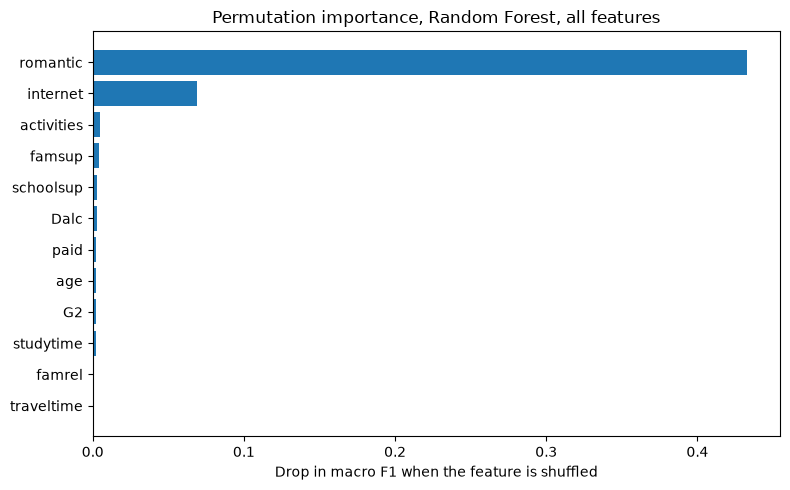

,association,measure,mutual_info,permutation_importance
feature,,,,
romantic,0.113,Cramers V,0.006,0.433
internet,0.107,Cramers V,0.006,0.069
activities,0.061,Cramers V,0.002,0.005
famsup,0.060,Cramers V,0.002,0.004
schoolsup,0.175,Cramers V,0.019,0.003
Dalc,0.150,abs Spearman,0.027,0.003
paid,0.106,Cramers V,0.006,0.002
age,0.191,abs Spearman,0.042,0.002
G2,0.902,abs Spearman,0.798,0.002


In [27]:
# ===== Build the feature evidence table and figure (Mathematics file) =====
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 42
Path("../outputs/tables").mkdir(parents=True, exist_ok=True)
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)


def assign_risk(g3):
    if g3 <= 9:
        return "High"
    elif g3 <= 13:
        return "Medium"
    return "Low"


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))


df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df["risk"] = df["G3"].apply(assign_risk)
risk_rank = df["risk"].map({"Low": 0, "Medium": 1, "High": 2})

feature_cols = [c for c in df.columns if c not in ["G3", "risk"]]
numeric_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(df[c])]
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

# Association with the risk band
rows = []
for col in numeric_cols:
    rho, _ = spearmanr(df[col], risk_rank)
    rows.append({"feature": col, "association": abs(rho), "measure": "abs Spearman"})
for col in categorical_cols:
    rows.append({"feature": col, "association": cramers_v(df[col], df["risk"]),
                 "measure": "Cramers V"})
evidence = pd.DataFrame(rows).set_index("feature")

# Mutual information
X_all = df[feature_cols].copy()
for col in categorical_cols:
    X_all[col] = X_all[col].astype("category").cat.codes

discrete_mask = [X_all[c].nunique() <= 10 for c in X_all.columns]
evidence["mutual_info"] = pd.Series(
    mutual_info_classif(X_all, df["risk"], discrete_features=discrete_mask,
                        random_state=RANDOM_STATE),
    index=X_all.columns,
)

# Permutation importance, averaged over five folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_scores = []
for train_idx, test_idx in skf.split(X_all, df["risk"]):
    forest = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=RANDOM_STATE, n_jobs=-1)
    forest.fit(X_all.iloc[train_idx], df["risk"].iloc[train_idx])
    result = permutation_importance(
        forest, X_all.iloc[test_idx], df["risk"].iloc[test_idx],
        scoring="f1_macro", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
    )
    fold_scores.append(result.importances_mean)

evidence["permutation_importance"] = np.mean(fold_scores, axis=0)
evidence = evidence.sort_values("permutation_importance", ascending=False).round(3)
evidence.to_csv("../outputs/tables/feature_evidence.csv")

# Figure
top = evidence.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["permutation_importance"])
plt.xlabel("Drop in macro F1 when the feature is shuffled")
plt.title("Permutation importance, Random Forest, all features")
plt.tight_layout()
plt.savefig("../outputs/figures/permutation_importance.png", dpi=200)
plt.show()

evidence.head(12)

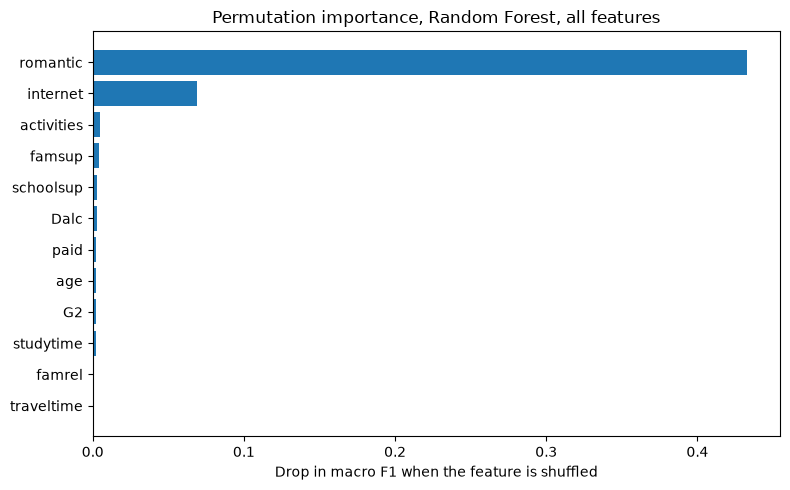

,association,measure,mutual_info,permutation_importance
feature,,,,
romantic,0.113,Cramers V,0.006,0.433
internet,0.107,Cramers V,0.006,0.069
activities,0.061,Cramers V,0.002,0.005
famsup,0.060,Cramers V,0.002,0.004
schoolsup,0.175,Cramers V,0.019,0.003
Dalc,0.150,abs Spearman,0.027,0.003
paid,0.106,Cramers V,0.006,0.002
age,0.191,abs Spearman,0.042,0.002
G2,0.902,abs Spearman,0.798,0.002


In [28]:
# ===== Build the feature evidence table and figure (Mathematics file) =====
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 42
Path("../outputs/tables").mkdir(parents=True, exist_ok=True)
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)


def assign_risk(g3):
    if g3 <= 9:
        return "High"
    elif g3 <= 13:
        return "Medium"
    return "Low"


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))


df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df["risk"] = df["G3"].apply(assign_risk)
risk_rank = df["risk"].map({"Low": 0, "Medium": 1, "High": 2})

feature_cols = [c for c in df.columns if c not in ["G3", "risk"]]
numeric_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(df[c])]
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

# Association with the risk band
rows = []
for col in numeric_cols:
    rho, _ = spearmanr(df[col], risk_rank)
    rows.append({"feature": col, "association": abs(rho), "measure": "abs Spearman"})
for col in categorical_cols:
    rows.append({"feature": col, "association": cramers_v(df[col], df["risk"]),
                 "measure": "Cramers V"})
evidence = pd.DataFrame(rows).set_index("feature")

# Mutual information
X_all = df[feature_cols].copy()
for col in categorical_cols:
    X_all[col] = X_all[col].astype("category").cat.codes

discrete_mask = [X_all[c].nunique() <= 10 for c in X_all.columns]
evidence["mutual_info"] = pd.Series(
    mutual_info_classif(X_all, df["risk"], discrete_features=discrete_mask,
                        random_state=RANDOM_STATE),
    index=X_all.columns,
)

# Permutation importance, averaged over five folds
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_scores = []
for train_idx, test_idx in skf.split(X_all, df["risk"]):
    forest = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=RANDOM_STATE, n_jobs=-1)
    forest.fit(X_all.iloc[train_idx], df["risk"].iloc[train_idx])
    result = permutation_importance(
        forest, X_all.iloc[test_idx], df["risk"].iloc[test_idx],
        scoring="f1_macro", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1,
    )
    fold_scores.append(result.importances_mean)

evidence["permutation_importance"] = np.mean(fold_scores, axis=0)
evidence = evidence.sort_values("permutation_importance", ascending=False).round(3)
evidence.to_csv("../outputs/tables/feature_evidence.csv")

# Figure
top = evidence.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["permutation_importance"])
plt.xlabel("Drop in macro F1 when the feature is shuffled")
plt.title("Permutation importance, Random Forest, all features")
plt.tight_layout()
plt.savefig("../outputs/figures/permutation_importance.png", dpi=200)
plt.show()

evidence.head(12)

In [29]:
# ===== Recreate the feature set table from the earlier printed result =====
import pandas as pd
from pathlib import Path

Path("../outputs/tables").mkdir(parents=True, exist_ok=True)

feature_sets = pd.DataFrame({
    "feature_set": ["G1, G2 and all others", "G1 and all others, no G2",
                    "G1 and G2 only", "No grades"],
    "recall_high": [0.884, 0.737, 0.885, 0.478],
    "recall_high_sd": [0.052, 0.076, 0.083, 0.072],
    "recall_macro": [0.876, 0.734, 0.874, 0.488],
    "f1_macro": [0.874, 0.730, 0.872, 0.485],
    "accuracy": [0.865, 0.719, 0.865, 0.488],
})

feature_sets.to_csv("../outputs/tables/cv_feature_sets.csv", index=False)
feature_sets

,feature_set,recall_high,recall_high_sd,recall_macro,f1_macro,accuracy
0,"G1, G2 and all others",0.884,0.052,0.876,0.874,0.865
1,"G1 and all others, no G2",0.737,0.076,0.734,0.730,0.719
2,G1 and G2 only,0.885,0.083,0.874,0.872,0.865
3,No grades,0.478,0.072,0.488,0.485,0.488
